# Práctica 1: Adquisición y representación de imágenes de productos

**Integrantes:** Angel Lucero y Fernando Mejia.

**Objetivo:** analizar fotos de productos y comparar RGB, gris y HSV para separar el color verde de un envase.


## 1. Planteamiento del problema, requisitos y restricciones

Queremos separar el verde del envase de Milo del resto de la foto. Las sombras, los reflejos y los objetos del fondo pueden hacer que se pierdan partes del envase o se seleccionen zonas ajenas.

Nosotros tomamos y analizamos las fotos; el docente revisa el procedimiento y los resultados.

| Prioridad | Requisito | Cómo lo comprobamos |
|---|---|---|
| Alta | Cargar imágenes propias y públicas | Galerías y revisión de etiquetas |
| Alta | Comparar resolución, profundidad y espacios de color | Tablas, canales e histogramas |
| Alta | Separar el verde del envase | Máscaras RGB y HSV con sus porcentajes |
| Media | Revisar clases y archivos | Conteos, lectura y búsqueda de duplicados |

**Restricciones:** trabajamos con nueve fotos de dos productos, fondos variados e iluminación sin controlar. No tenemos registrados la cámara ni la distancia. Usamos OpenCV en el equipo disponible; no se definieron un presupuesto ni un tiempo máximo de procesamiento.

**Observación:** las fotos permiten estudiar el color, pero no comparar únicamente el efecto de la luz.

**Conclusión:** consideramos logrado el análisis si podemos cargar las imágenes, mostrar las conversiones y explicar las máscaras. El porcentaje seleccionado mide área, no exactitud de detección.


## 2. Construcción y análisis del dataset

### 2.1 Carga de imágenes

Cargamos las fotos propias y la copia local de Grocery Store Dataset. Conservamos los originales y guardamos los resultados en `practica1/resultados/cuaderno`.


In [1]:
%matplotlib inline
from pathlib import Path
from collections import Counter
import csv
import hashlib
import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

candidatas = [Path.cwd(), *Path.cwd().parents]
BASE = next((p for p in candidatas if (p / 'practica1' / 'imagenes').is_dir()), None)
if BASE is None:
    raise FileNotFoundError('Abre el notebook dentro del proyecto VISION POR COMPUTADOR.')
ENTRADA = BASE / 'practica1' / 'imagenes'
SALIDA = BASE / 'practica1' / 'resultados' / 'cuaderno'
SALIDA.mkdir(parents=True, exist_ok=True)
extensiones = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'}
archivos = sorted(p for p in ENTRADA.iterdir() if p.suffix.lower() in extensiones)
if not archivos:
    raise ValueError('Agrega fotografías a practica1/imagenes.')

def leer(ruta):
    foto = cv2.imdecode(np.fromfile(str(ruta), dtype=np.uint8), cv2.IMREAD_COLOR)
    if foto is None:
        raise ValueError(f'Imagen no legible: {ruta}')
    return foto

def tabla(filas, columnas):
    texto = '| ' + ' | '.join(columnas) + ' |\n'
    texto += '| ' + ' | '.join(['---'] * len(columnas)) + ' |\n'
    texto += '\n'.join('| ' + ' | '.join(str(f[c]) for c in columnas) + ' |' for f in filas)
    display(Markdown(texto))

print(f'Fotografías propias disponibles: {len(archivos)}')
print(f'Resultados: {SALIDA}')


Fotografías propias disponibles: 9
Resultados: C:\C_PROJECTS\VISION POR COMPUTADOR\practica1\resultados\cuaderno


### 2.2 Fotografías propias

Agrupamos las fotos en dos clases: Milo y leche condensada. La siguiente galería permite revisar el producto, la vista y el fondo de cada captura.


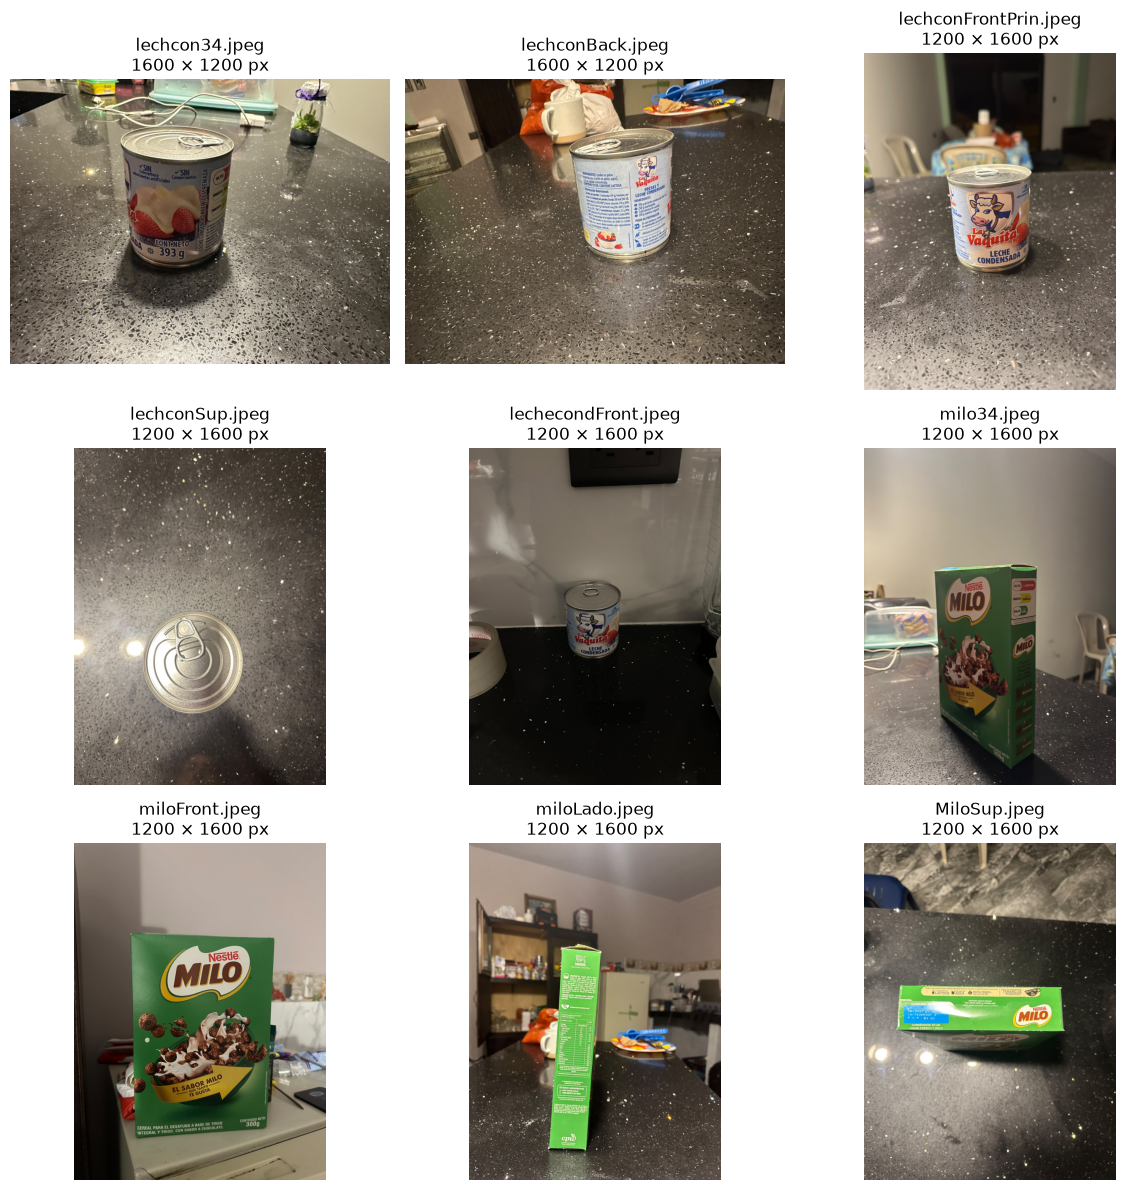

lechcon34.jpeg: 1.92 MP | 24 bits/píxel | matriz: 5760000 bytes | archivo: 382231 bytes
lechconBack.jpeg: 1.92 MP | 24 bits/píxel | matriz: 5760000 bytes | archivo: 355254 bytes
lechconFrontPrin.jpeg: 1.92 MP | 24 bits/píxel | matriz: 5760000 bytes | archivo: 253478 bytes
lechconSup.jpeg: 1.92 MP | 24 bits/píxel | matriz: 5760000 bytes | archivo: 239226 bytes
lechecondFront.jpeg: 1.92 MP | 24 bits/píxel | matriz: 5760000 bytes | archivo: 76643 bytes
milo34.jpeg: 1.92 MP | 24 bits/píxel | matriz: 5760000 bytes | archivo: 139328 bytes
miloFront.jpeg: 1.92 MP | 24 bits/píxel | matriz: 5760000 bytes | archivo: 140072 bytes
miloLado.jpeg: 1.92 MP | 24 bits/píxel | matriz: 5760000 bytes | archivo: 220237 bytes
MiloSup.jpeg: 1.92 MP | 24 bits/píxel | matriz: 5760000 bytes | archivo: 203358 bytes


In [2]:
filas = []
figura, ejes = plt.subplots((len(archivos) + 2) // 3, 3, figsize=(12, 4 * ((len(archivos) + 2) // 3)))
for eje in np.asarray(ejes).flat:
    eje.axis("off")
for eje, ruta in zip(np.asarray(ejes).flat, archivos):
    foto = cv2.imdecode(np.fromfile(str(ruta), dtype=np.uint8), cv2.IMREAD_COLOR)
    if foto is None:
        raise ValueError(f"No se pudo leer {ruta.name}")
    alto, ancho, canales = foto.shape
    filas.append({"archivo": ruta.name, "ancho_px": ancho, "alto_px": alto,
                  "megapixeles": round(ancho * alto / 1_000_000, 3),
                  "canales": canales, "bits_por_canal": foto.dtype.itemsize * 8,
                  "bits_por_pixel": foto.dtype.itemsize * 8 * canales,
                  "memoria_bytes": foto.nbytes, "archivo_bytes": ruta.stat().st_size})
    eje.imshow(cv2.cvtColor(foto, cv2.COLOR_BGR2RGB))
    eje.set_title(f"{ruta.name}\n{ancho} × {alto} px")
figura.tight_layout()
plt.show()
for fila in filas:
    print(f"{fila['archivo']}: {fila['megapixeles']} MP | {fila['bits_por_pixel']} bits/píxel | matriz: {fila['memoria_bytes']} bytes | archivo: {fila['archivo_bytes']} bytes")

| archivo | ancho_px | alto_px | megapixeles | bits_por_canal | bits_por_pixel | memoria_bytes | archivo_bytes |
| --- | --- | --- | --- | --- | --- | --- | --- |
| lechcon34.jpeg | 1600 | 1200 | 1.92 | 8 | 24 | 5760000 | 382231 |
| lechconBack.jpeg | 1600 | 1200 | 1.92 | 8 | 24 | 5760000 | 355254 |
| lechconFrontPrin.jpeg | 1200 | 1600 | 1.92 | 8 | 24 | 5760000 | 253478 |
| lechconSup.jpeg | 1200 | 1600 | 1.92 | 8 | 24 | 5760000 | 239226 |
| lechecondFront.jpeg | 1200 | 1600 | 1.92 | 8 | 24 | 5760000 | 76643 |
| milo34.jpeg | 1200 | 1600 | 1.92 | 8 | 24 | 5760000 | 139328 |
| miloFront.jpeg | 1200 | 1600 | 1.92 | 8 | 24 | 5760000 | 140072 |
| miloLado.jpeg | 1200 | 1600 | 1.92 | 8 | 24 | 5760000 | 220237 |
| MiloSup.jpeg | 1200 | 1600 | 1.92 | 8 | 24 | 5760000 | 203358 |

| producto | fotografias | porcentaje |
| --- | --- | --- |
| Leche condensada | 5 | 55.56 |
| Milo | 4 | 44.44 |

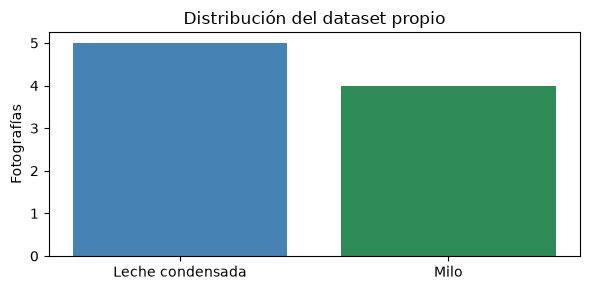

In [3]:
tabla(filas, ['archivo', 'ancho_px', 'alto_px', 'megapixeles', 'bits_por_canal',
              'bits_por_pixel', 'memoria_bytes', 'archivo_bytes'])
clases_propias = Counter('Milo' if p.stem.lower().startswith('milo') else 'Leche condensada' for p in archivos)
tabla([{'producto': k, 'fotografias': v, 'porcentaje': round(100*v/len(archivos), 2)}
       for k, v in clases_propias.items()], ['producto', 'fotografias', 'porcentaje'])
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(list(clases_propias), list(clases_propias.values()), color=['steelblue', 'seagreen'])
ax.set_ylabel('Fotografías'); ax.set_title('Distribución del dataset propio')
fig.tight_layout(); plt.show()


**Observación:** tenemos cinco fotos de leche condensada y cuatro de Milo. Todas tienen 1,92 MP y se cargan con tres canales de 8 bits: 24 bits por píxel. Cada matriz ocupa 5,76 MB, aunque el tamaño JPEG cambia. Se ven reflejos, sombras y objetos de fondo.

**Conclusión:** podemos comparar distintas vistas, pero la variedad es pequeña. Tener la misma resolución no implica tener el mismo tamaño de archivo.

### 2.3 Dataset público

Usamos **Grocery Store Dataset**, con fotos tomadas en tiendas y etiquetas por producto. Leemos las clases desde `classes.csv` y las particiones desde `train.txt`, `val.txt` y `test.txt`.

Revisamos que los archivos se abran, que las etiquetas coincidan y que no haya rutas ni archivos idénticos repetidos. Registramos los problemas sin borrar imágenes ni cambiar las particiones.


| particion | imagenes | clases_finas |
| --- | --- | --- |
| train | 2640 | 81 |
| val | 296 | 60 |
| test | 2485 | 81 |

| ancho | alto | imagenes |
| --- | --- | --- |
| 348 | 348 | 4958 |
| 348 | 464 | 426 |
| 464 | 348 | 37 |

Catálogo: 81 clases finas; 43 generales.
Incidencias: 0; duplicados exactos adicionales: 0


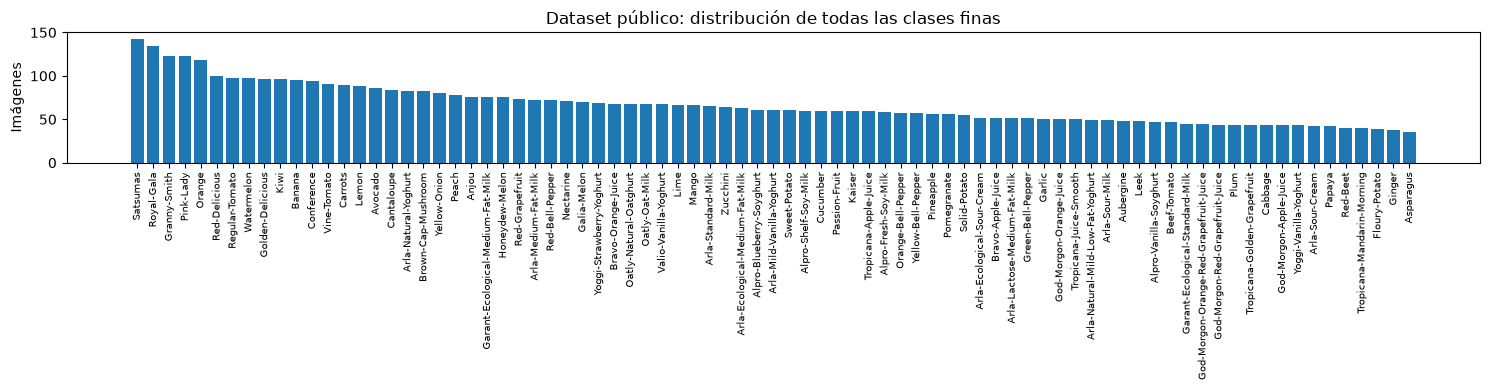

**Observación:** cargamos 5421 imágenes de 81 clases, con 3 resoluciones. Hay entre 35 y 143 fotos por clase; encontramos 0 incidencias y 0 duplicados exactos.

**Conclusión:** las clases tienen cantidades distintas; una evaluación debe tenerlo en cuenta.

In [4]:
opciones = [BASE / 'CLASES/datos/GroceryStoreDataset/dataset',
            BASE / 'practica1/datos/GroceryStoreDataset/dataset']
PUBLICO = next((p for p in opciones if (p / 'classes.csv').is_file()), None)
if PUBLICO is None:
    raise FileNotFoundError('Falta la copia de GroceryStoreDataset indicada en §2.1.')
with (PUBLICO / 'classes.csv').open(encoding='utf-8-sig', newline='') as f:
    catalogo = list(csv.DictReader(f))
etiquetas = {int(r['Class ID (int)']): r for r in catalogo}
registros, incidencias, hashes, rutas_vistas = [], [], {}, set()
duplicados = []
for particion in ['train', 'val', 'test']:
    with (PUBLICO / f'{particion}.txt').open(encoding='utf-8-sig', newline='') as f:
        for linea in csv.reader(f):
            if not linea:
                continue
            relativa, fina, general = [s.strip() for s in linea]
            fina, general = int(fina), int(general)
            destino = PUBLICO / relativa.lstrip('/')
            problemas = []
            etiqueta = etiquetas.get(fina)
            if etiqueta is None or int(etiqueta['Coarse Class ID (int)']) != general:
                problemas.append('Etiquetas fina/general incompatibles')
            if relativa in rutas_vistas:
                problemas.append('Ruta repetida en manifiestos')
            rutas_vistas.add(relativa)
            if not destino.is_file():
                problemas.append('Archivo ausente')
                foto = None
            else:
                foto = cv2.imdecode(np.fromfile(str(destino), dtype=np.uint8), cv2.IMREAD_COLOR)
                if foto is None:
                    problemas.append('Archivo ilegible')
                digest = hashlib.sha256(destino.read_bytes()).hexdigest()
                if digest in hashes:
                    duplicados.append({'primero': hashes[digest], 'repetido': relativa})
                else:
                    hashes[digest] = relativa
            for problema in problemas:
                incidencias.append({'archivo': relativa, 'problema': problema})
            if foto is not None and etiqueta is not None and not problemas:
                registros.append({'archivo': relativa, 'particion': particion, 'id': fina,
                    'clase': etiqueta['Class Name (str)'],
                    'general': etiqueta['Coarse Class Name (str)'],
                    'ancho': foto.shape[1], 'alto': foto.shape[0]})
if not registros:
    raise ValueError('No se encontraron imágenes públicas válidas.')
conteos = Counter(r['clase'] for r in registros)
resoluciones = Counter((r['ancho'], r['alto']) for r in registros)
tabla([{'particion': p, 'imagenes': sum(r['particion'] == p for r in registros),
        'clases_finas': len({r['id'] for r in registros if r['particion'] == p})}
       for p in ['train', 'val', 'test']], ['particion', 'imagenes', 'clases_finas'])
tabla([{'ancho': a, 'alto': b, 'imagenes': n} for (a,b), n in resoluciones.most_common()],
      ['ancho', 'alto', 'imagenes'])
print(f'Catálogo: {len(etiquetas)} clases finas; {len({r["Coarse Class ID (int)"] for r in catalogo})} generales.')
print(f'Incidencias: {len(incidencias)}; duplicados exactos adicionales: {len(duplicados)}')
if incidencias:
    tabla(incidencias[:20], ['archivo', 'problema'])
if duplicados:
    tabla(duplicados[:20], ['primero', 'repetido'])
for nombre, datos, columnas in [
    ('inventario_publico.csv', registros, list(registros[0])),
    ('incidencias_publico.csv', incidencias, ['archivo', 'problema']),
    ('duplicados_publico.csv', duplicados, ['primero', 'repetido'])]:
    with (SALIDA / nombre).open('w', encoding='utf-8-sig', newline='') as f:
        w = csv.DictWriter(f, fieldnames=columnas); w.writeheader(); w.writerows(datos)
fig, ax = plt.subplots(figsize=(15, 4))
orden = sorted(conteos.items(), key=lambda par: (-par[1], par[0]))
ax.bar(range(len(orden)), [n for _, n in orden])
ax.set_xticks(range(len(orden)), [c for c, _ in orden], rotation=90, fontsize=7)
ax.set_ylabel('Imágenes'); ax.set_title('Dataset público: distribución de todas las clases finas')
fig.tight_layout(); plt.show()
menor, mayor = min(conteos.values()), max(conteos.values())
display(Markdown(f'**Observación:** cargamos {len(registros)} imágenes de {len(conteos)} clases, '
    f'con {len(resoluciones)} resoluciones. Hay entre {menor} y {mayor} fotos por clase; '
    f'encontramos {len(incidencias)} incidencias y {len(duplicados)} duplicados exactos.\n\n'
    '**Conclusión:** las clases tienen cantidades distintas; una evaluación debe tenerlo en cuenta.'))


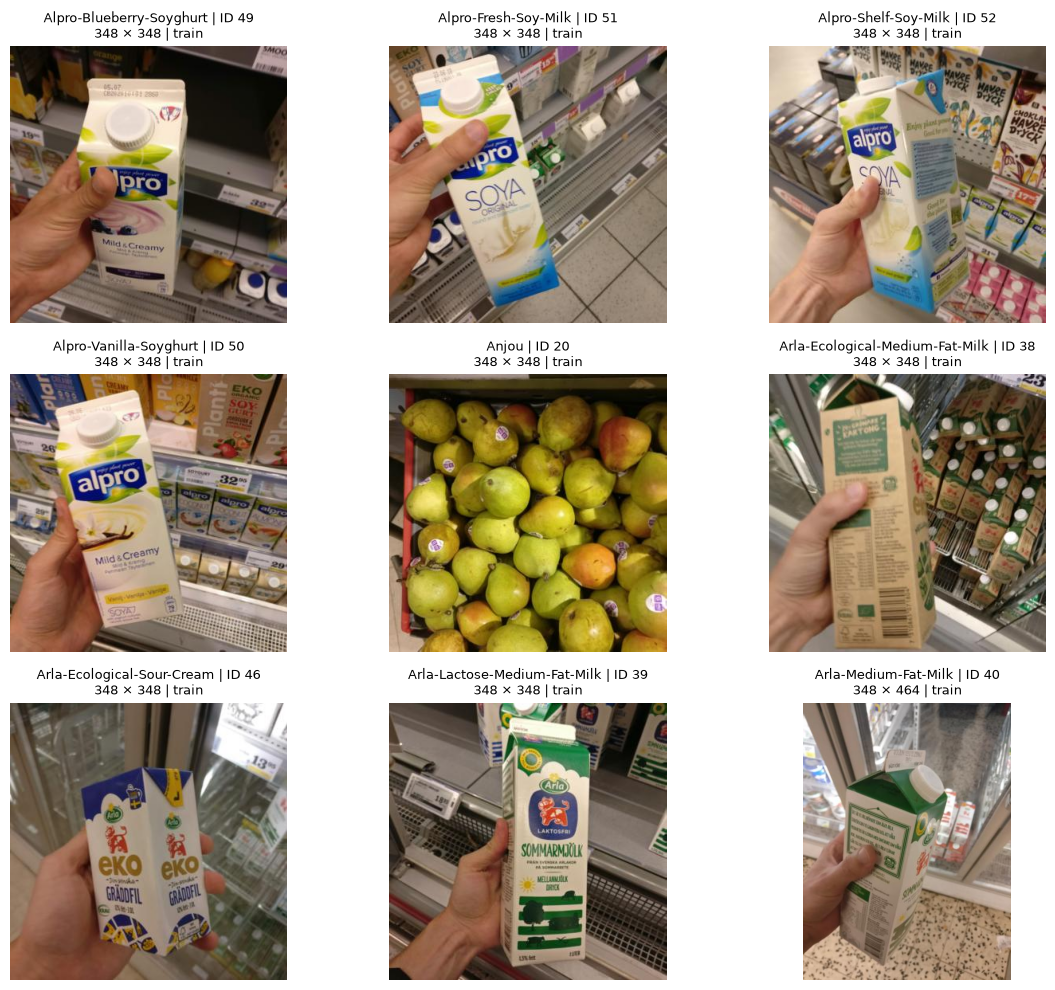

| archivo | id | clase | general |
| --- | --- | --- | --- |
| train/Packages/Soyghurt/Alpro-Blueberry-Soyghurt/Alpro-Blueberry-Soyghurt_001.jpg | 49 | Alpro-Blueberry-Soyghurt | Soyghurt |
| train/Packages/Soy-Milk/Alpro-Fresh-Soy-Milk/Alpro-Fresh-Soy-Milk_001.jpg | 51 | Alpro-Fresh-Soy-Milk | Soy-Milk |
| train/Packages/Soy-Milk/Alpro-Shelf-Soy-Milk/Alpro-Shelf-Soy-Milk_001.jpg | 52 | Alpro-Shelf-Soy-Milk | Soy-Milk |
| train/Packages/Soyghurt/Alpro-Vanilla-Soyghurt/Alpro-Vanilla-Soyghurt_001.jpg | 50 | Alpro-Vanilla-Soyghurt | Soyghurt |
| train/Fruit/Pear/Anjou/Anjou_001.jpg | 20 | Anjou | Pear |
| train/Packages/Milk/Arla-Ecological-Medium-Fat-Milk/Arla-Ecological-Medium-Fat-Milk_001.jpg | 38 | Arla-Ecological-Medium-Fat-Milk | Milk |
| train/Packages/Sour-Cream/Arla-Ecological-Sour-Cream/Arla-Ecological-Sour-Cream_001.jpg | 46 | Arla-Ecological-Sour-Cream | Sour-Cream |
| train/Packages/Milk/Arla-Lactose-Medium-Fat-Milk/Arla-Lactose-Medium-Fat-Milk_001.jpg | 39 | Arla-Lactose-Medium-Fat-Milk | Milk |
| train/Packages/Milk/Arla-Medium-Fat-Milk/Arla-Medium-Fat-Milk_001.jpg | 40 | Arla-Medium-Fat-Milk | Milk |

In [5]:
# Muestra determinista: una imagen de nueve clases distintas.
ejemplos = []
for clase in sorted(conteos)[:9]:
    ejemplos.append(next(r for r in registros if r['clase'] == clase))
fig, ejes = plt.subplots(3, 3, figsize=(12, 10))
for ax, r in zip(ejes.flat, ejemplos):
    ax.imshow(cv2.cvtColor(leer(PUBLICO / r['archivo']), cv2.COLOR_BGR2RGB))
    ax.set_title(f"{r['clase']} | ID {r['id']}\n{r['ancho']} × {r['alto']} | {r['particion']}", fontsize=9)
    ax.axis('off')
fig.tight_layout(); plt.show()
tabla(ejemplos, ['archivo', 'id', 'clase', 'general'])


**Observación:** en los ejemplos públicos también cambian los fondos y la presentación de los productos. Revisamos visualmente estas nueve muestras y comprobamos los identificadores de todo el conjunto.

**Conclusión:** el dataset público aporta variedad. Lo analizamos por separado porque sus clases son distintas de las nuestras.


## 3. Representación de la imagen y espacios de color

### 3.1 Imagen seleccionada

Elegimos `miloFront.jpeg` porque el verde del envase se distingue bien. Para probar otra foto, cambia `NOMBRE_IMAGEN`, `COLOR` y `UMBRAL`.


Resolución: 1200 × 1600 píxeles
Profundidad cargada: 8 bits por canal
Canales: 3
Tipo de dato: uint8


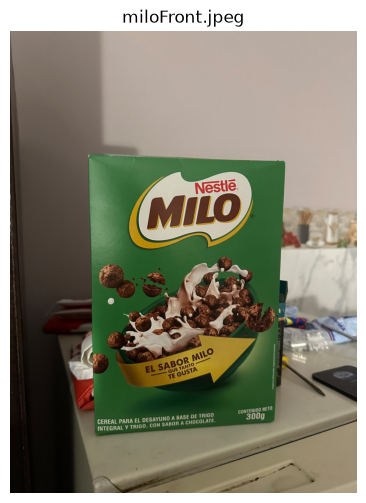

In [6]:
NOMBRE_IMAGEN = "miloFront.jpeg"
COLOR = "verde"
UMBRAL = 127

ruta = ENTRADA / NOMBRE_IMAGEN
imagen = cv2.imdecode(np.fromfile(str(ruta), dtype=np.uint8), cv2.IMREAD_COLOR)
if imagen is None:
    raise ValueError(f"No se pudo leer {NOMBRE_IMAGEN}")
rgb = cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)
alto, ancho, canales = imagen.shape
print(f"Resolución: {ancho} × {alto} píxeles")
print(f"Profundidad cargada: {imagen.dtype.itemsize * 8} bits por canal")
print(f"Canales: {canales}")
print(f"Tipo de dato: {imagen.dtype}")
plt.figure(figsize=(6, 6))
plt.imshow(rgb)
plt.title(NOMBRE_IMAGEN)
plt.axis("off")
plt.show()

**Observación:** además del envase hay varios objetos de fondo. **Conclusión:** debemos revisar qué zonas selecciona la máscara.

### 3.2 RGB, gris y blanco y negro

Convertimos BGR a RGB para mostrar los colores correctamente. Gris combina los canales y binario separa las intensidades con un umbral de 127. La imagen cargada tiene 256 niveles por canal; la binaria solo usa 0 y 255, aunque se almacena en 8 bits por píxel.


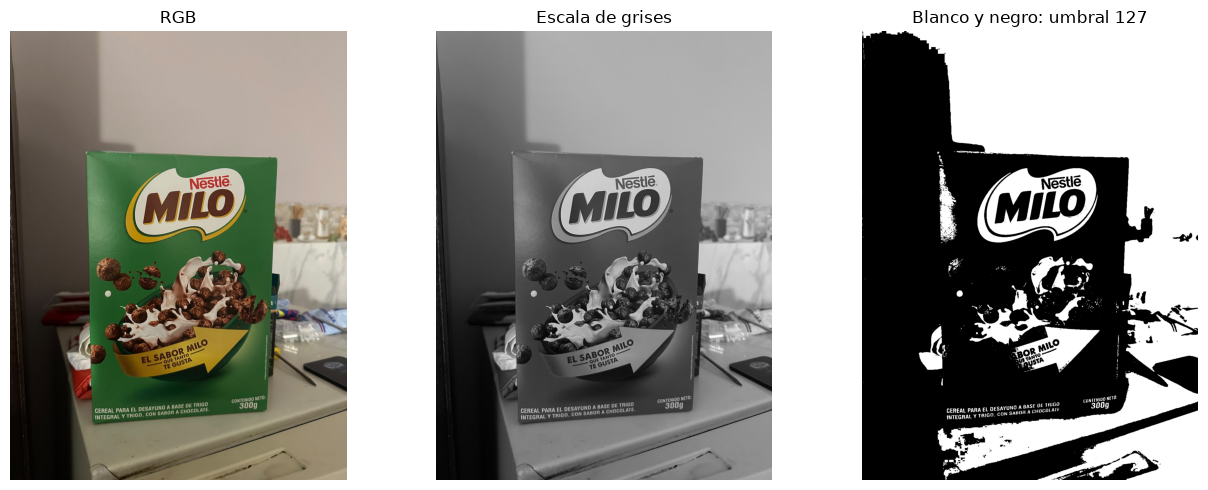

In [7]:
gris = cv2.cvtColor(imagen, cv2.COLOR_BGR2GRAY)
_, binaria = cv2.threshold(gris, UMBRAL, 255, cv2.THRESH_BINARY)
figura, ejes = plt.subplots(1, 3, figsize=(13, 5))
for eje, vista, titulo in zip(ejes, [rgb, gris, binaria], ["RGB", "Escala de grises", f"Blanco y negro: umbral {UMBRAL}"]):
    eje.imshow(vista, cmap="gray", vmin=0, vmax=255)
    eje.set_title(titulo)
    eje.axis("off")
figura.tight_layout()
figura.savefig(SALIDA / f"{ruta.stem}_representaciones.png", dpi=150)
plt.show()

In [8]:
blancos = 100 * np.count_nonzero(binaria) / binaria.size
display(Markdown(f'**Observación:** con umbral {UMBRAL}, el {blancos:.2f}% queda blanco y el '
    f'{100-blancos:.2f}% negro.\n\n'
    '**Conclusión:** RGB conserva el color; gris permite ver intensidades y contornos. '
    'El binario simplifica la imagen, pero este umbral no separa el verde.'))


**Observación:** con umbral 127, el 44.36% queda blanco y el 55.64% negro.

**Conclusión:** RGB conserva el color; gris permite ver intensidades y contornos. El binario simplifica la imagen, pero este umbral no separa el verde.

### 3.3 Espacio HSV

HSV separa tono (H), saturación (S) y brillo (V). En OpenCV, H va de 0 a 179; S y V, de 0 a 255. Mostramos cada canal por separado.


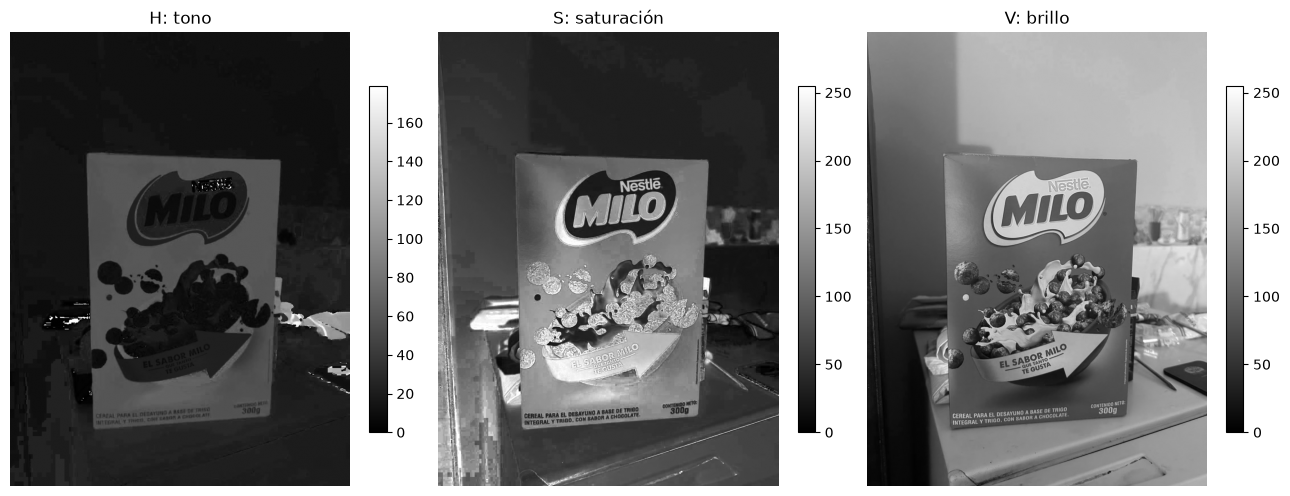

In [9]:
hsv = cv2.cvtColor(imagen, cv2.COLOR_BGR2HSV)
h, s, v = cv2.split(hsv)
figura, ejes = plt.subplots(1, 3, figsize=(13, 5))
for eje, canal, titulo, limite in zip(ejes, [h, s, v], ["H: tono", "S: saturación", "V: brillo"], [179, 255, 255]):
    vista = eje.imshow(canal, cmap="gray", vmin=0, vmax=limite)
    figura.colorbar(vista, ax=eje, fraction=0.046)
    eje.set_title(titulo)
    eje.axis("off")
figura.tight_layout()
figura.savefig(SALIDA / f"{ruta.stem}_hsv.png", dpi=150)
plt.show()

**Observación:** H distingue tonos, S resalta los colores más saturados y V las zonas más brillantes.

**Conclusión:** para buscar verde conviene combinar los tres canales; el tono por sí solo es poco fiable en zonas casi grises.

### 3.4 Histogramas

Los histogramas muestran cuántos píxeles hay en cada valor. En gris, los valores bajos son oscuros y los altos son claros.


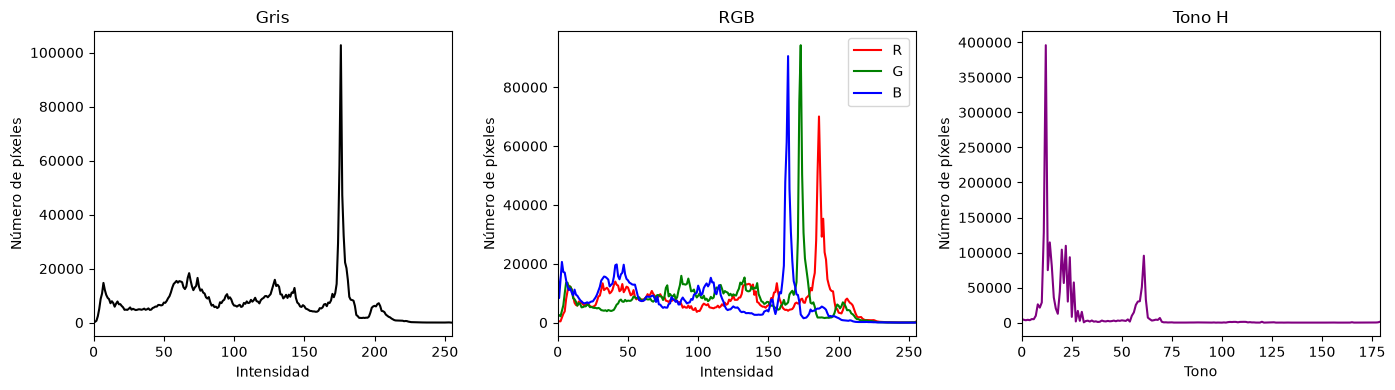

In [10]:
figura, ejes = plt.subplots(1, 3, figsize=(14, 4))
ejes[0].plot(cv2.calcHist([gris], [0], None, [256], [0, 256]), color="black")
ejes[0].set_title("Gris")
for indice, color, nombre in zip(range(3), ["red", "green", "blue"], ["R", "G", "B"]):
    histograma = cv2.calcHist([rgb], [indice], None, [256], [0, 256])
    ejes[1].plot(histograma, color=color, label=nombre)
ejes[1].set_title("RGB")
ejes[1].legend()
ejes[2].plot(cv2.calcHist([hsv], [0], None, [180], [0, 180]), color="purple")
ejes[2].set_title("Tono H")
for indice, eje in enumerate(ejes):
    eje.set_xlabel("Tono" if indice == 2 else "Intensidad")
    eje.set_ylabel("Número de píxeles")
    eje.set_xlim(0, 179 if indice == 2 else 255)
figura.tight_layout()
figura.savefig(SALIDA / f"{ruta.stem}_histogramas.png", dpi=150)
plt.show()

In [11]:
pico_gris = int(np.argmax(np.bincount(gris.ravel(), minlength=256)))
picos_rgb = [int(np.argmax(np.bincount(rgb[:,:,i].ravel(), minlength=256))) for i in range(3)]
saturados = s >= 60
pico_h = int(np.argmax(np.bincount(h[saturados], minlength=180))) if saturados.any() else None
oscuros = 100 * np.mean(gris < 64)
claros = 100 * np.mean(gris >= 192)
display(Markdown(f'**Observación:** el pico gris está en {pico_gris}; los picos R/G/B son {picos_rgb}. '
    f'Con S ≥ 60, el pico de tono está en H = {pico_h}. El {oscuros:.2f}% es oscuro '
    f'(gris < 64) y el {claros:.2f}% es claro (gris ≥ 192).\n\n'
    '**Conclusión:** las sombras aportan valores bajos y las zonas iluminadas, altos. '
    'Hay que mirar la foto junto al histograma para interpretar esos valores.'))


**Observación:** el pico gris está en 176; los picos R/G/B son [186, 173, 164]. Con S ≥ 60, el pico de tono está en H = 61. El 24.44% es oscuro (gris < 64) y el 4.77% es claro (gris ≥ 192).

**Conclusión:** las sombras aportan valores bajos y las zonas iluminadas, altos. Hay que mirar la foto junto al histograma para interpretar esos valores.

### 3.5 Segmentación HSV

La máscara muestra en blanco los píxeles que cumplen el rango elegido. El porcentaje indica cuánto de la foto queda seleccionado.


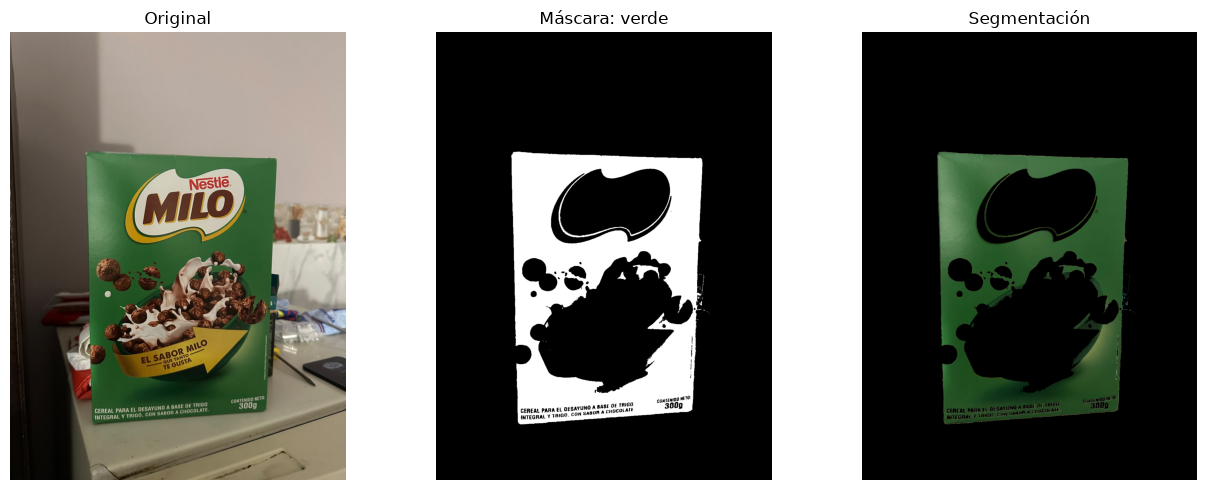

Porcentaje de píxeles seleccionados: 17.95%


In [12]:
rangos = {
    "rojo": [((0, 80, 50), (10, 255, 255)), ((170, 80, 50), (179, 255, 255))],
    "amarillo": [((20, 80, 50), (35, 255, 255))],
    "verde": [((36, 60, 40), (85, 255, 255))],
    "azul": [((90, 80, 50), (130, 255, 255))]
}
mascara = np.zeros(gris.shape, dtype=np.uint8)
for inferior, superior in rangos[COLOR]:
    parcial = cv2.inRange(hsv, np.array(inferior, dtype=np.uint8), np.array(superior, dtype=np.uint8))
    mascara = cv2.bitwise_or(mascara, parcial)
segmentada = cv2.bitwise_and(rgb, rgb, mask=mascara)
porcentaje = cv2.countNonZero(mascara) / mascara.size * 100
figura, ejes = plt.subplots(1, 3, figsize=(13, 5))
for eje, vista, titulo in zip(ejes, [rgb, mascara, segmentada], ["Original", f"Máscara: {COLOR}", "Segmentación"]):
    eje.imshow(vista, cmap="gray", vmin=0, vmax=255)
    eje.set_title(titulo)
    eje.axis("off")
figura.tight_layout()
figura.savefig(SALIDA / f"{ruta.stem}_segmentacion_{COLOR}.png", dpi=150)
plt.show()
print(f"Porcentaje de píxeles seleccionados: {porcentaje:.2f}%")

**Observación:** se selecciona buena parte del verde, pero quedan huecos en el logotipo, los dibujos y otras zonas del envase. Un objeto verde del fondo también podría entrar en la máscara.

**Conclusión:** esta técnica separa el color, pero no recupera necesariamente todo el producto.

### 3.6 Comparación RGB y HSV

Probamos las cuatro vistas de Milo con el mismo rango HSV. Como referencia RGB usamos G > 1,15R, G > 1,15B y G > 40. La IoU indica cuánto coinciden ambas máscaras; no mide acierto frente a una máscara manual.


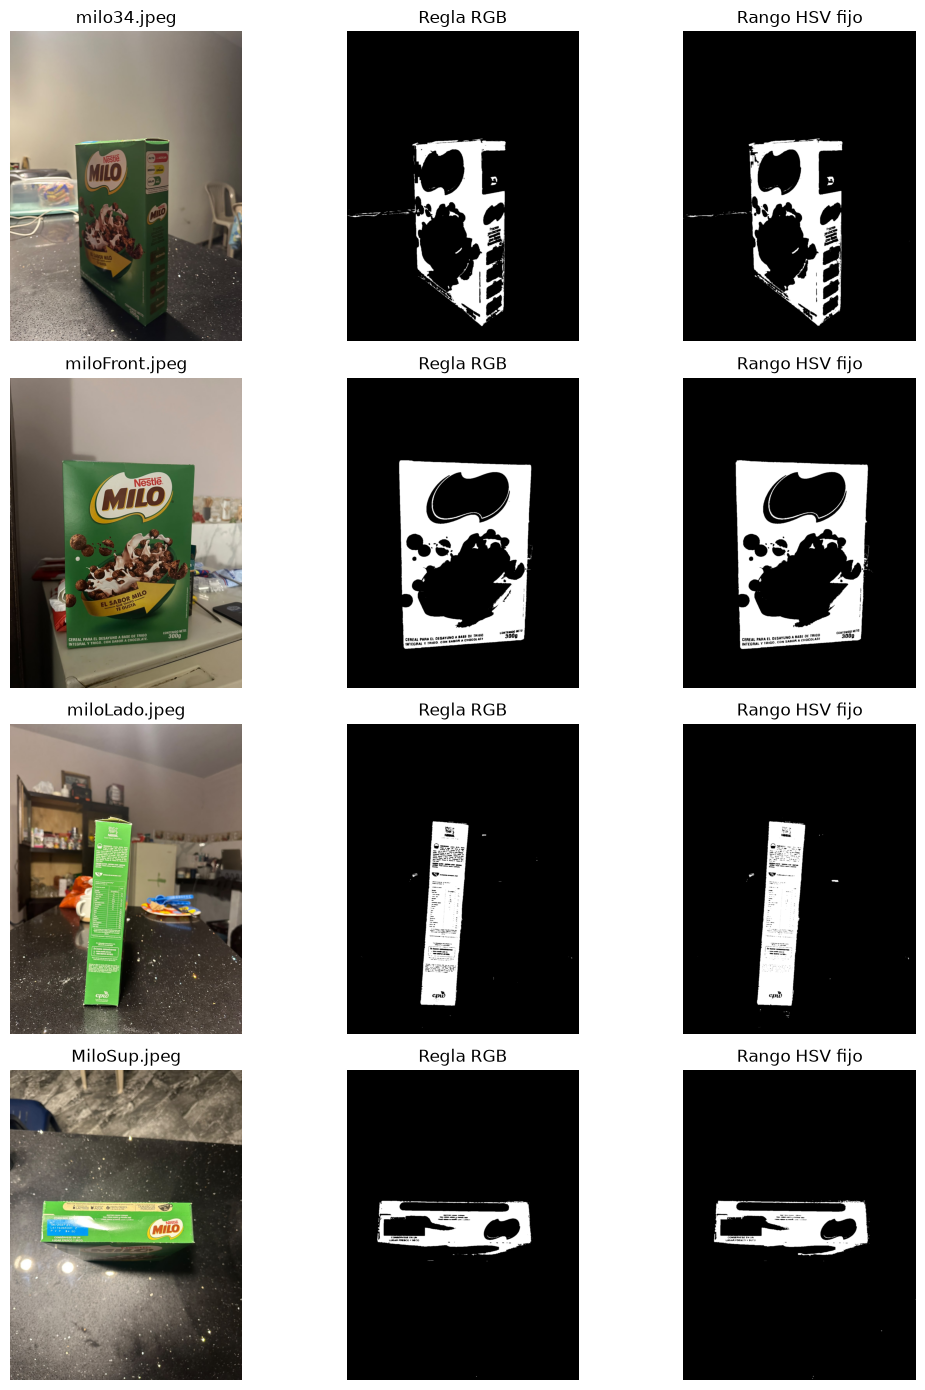

| archivo | HSV_area_pct | RGB_area_pct | IoU_entre_metodos |
| --- | --- | --- | --- |
| milo34.jpeg | 9.94 | 9.24 | 0.911 |
| miloFront.jpeg | 17.95 | 17.77 | 0.984 |
| miloLado.jpeg | 8.49 | 8.11 | 0.952 |
| MiloSup.jpeg | 5.9 | 5.71 | 0.951 |

In [13]:
comparacion = []
fotos_milo = [p for p in archivos if p.stem.lower().startswith('milo')]
fig, ejes = plt.subplots(len(fotos_milo), 3, figsize=(11, 3.5*len(fotos_milo)))
for ejes_fila, p in zip(ejes, fotos_milo):
    bgr_i = leer(p)
    rgb_i = cv2.cvtColor(bgr_i, cv2.COLOR_BGR2RGB)
    hsv_i = cv2.cvtColor(bgr_i, cv2.COLOR_BGR2HSV)
    mask_hsv = cv2.inRange(hsv_i, np.array((36,60,40), np.uint8), np.array((85,255,255), np.uint8)) > 0
    ri, gi, bi = rgb_i.astype(np.float32).transpose(2,0,1)
    mask_rgb = (gi > 1.15*ri) & (gi > 1.15*bi) & (gi > 40)
    union = np.count_nonzero(mask_hsv | mask_rgb)
    acuerdo = np.count_nonzero(mask_hsv & mask_rgb)/union if union else None
    comparacion.append({'archivo': p.name, 'HSV_area_pct': round(100*mask_hsv.mean(),2),
        'RGB_area_pct': round(100*mask_rgb.mean(),2),
        'IoU_entre_metodos': round(acuerdo,3) if acuerdo is not None else 'sin selección'})
    for ax, vista, titulo in zip(ejes_fila, [rgb_i, mask_rgb, mask_hsv],
                                [p.name, 'Regla RGB', 'Rango HSV fijo']):
        ax.imshow(vista, cmap='gray', vmin=0, vmax=1); ax.set_title(titulo); ax.axis('off')
fig.tight_layout(); fig.savefig(SALIDA / 'comparacion_rgb_hsv.png', dpi=120); plt.show()
tabla(comparacion, ['archivo', 'HSV_area_pct', 'RGB_area_pct', 'IoU_entre_metodos'])
with (SALIDA / 'comparacion_rgb_hsv.csv').open('w', newline='', encoding='utf-8-sig') as f:
    w = csv.DictWriter(f, fieldnames=list(comparacion[0])); w.writeheader(); w.writerows(comparacion)


**Observación:** ambas reglas seleccionan zonas parecidas del envase. El área cambia entre fotos porque también cambian la vista, la distancia y el fondo.

**Conclusión:** elegimos HSV porque permite ajustar tono, saturación y brillo por separado. Para comprobar su respuesta a la luz necesitamos repetir la captura con encuadre fijo.

### 3.7 Guardar resultados

Exportamos las figuras y las tablas para poder revisarlas después.


In [14]:
with (SALIDA / "caracteristicas.csv").open("w", newline="", encoding="utf-8-sig") as archivo:
    escritor = csv.DictWriter(archivo, fieldnames=filas[0].keys())
    escritor.writeheader()
    escritor.writerows(filas)
with (SALIDA / f"{ruta.stem}_segmentacion_{COLOR}.csv").open("w", newline="", encoding="utf-8-sig") as archivo:
    escritor = csv.writer(archivo)
    escritor.writerow(["imagen", "color", "umbral_binario", "porcentaje_seleccionado"])
    escritor.writerow([NOMBRE_IMAGEN, COLOR, UMBRAL, round(porcentaje, 2)])
print(f"Resultados guardados en {SALIDA}")

Resultados guardados en C:\C_PROJECTS\VISION POR COMPUTADOR\practica1\resultados\cuaderno


## 4. Conclusiones

- RGB conserva los colores; gris los pierde y binario elimina también los tonos intermedios.
- HSV nos ayuda a separar el verde, aunque las sombras, los reflejos y el fondo siguen influyendo.
- Las imágenes y los histogramas permiten explicar el resultado; una máscara por sí sola no demuestra que se reconozca el producto.

